In [1]:
#| label: import
import itertools
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import comb
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import lime
import lime.lime_tabular

np.random.seed(123456)

## Solution 1: The Shapley value

In [2]:
#| label: payoff
def payoff(coalition):
    # Define boolean variables that indicate whether Timnit, Margret, Samy,
    # Jeff and Larry are in the set or not.
    t = 't' in coalition
    s = 's' in coalition
    m = 'm' in coalition
    j = 'j' in coalition
    l = 'l' in coalition
    return 10*t + 10*m + 10*s + 2*j + 20 * (t and m) + 20 * (t and m and s) - 30 * ((t or m or s) and j)


# Testing, including the corner cases empty set and full population.
population = ['j', 'l', 'm', 's', 't']
print(payoff(('t', 'm')))
print(payoff(['t', 'j', 's']))
print(payoff([]))
print(payoff(population))

40
-8
0
42


In [3]:
#| label: all-unique-subsets
def all_unique_subsets(population):
    """Recursive power set: pick an element, compute the power set of the
    rest, return those subsets with and without the picked element."""
    if not population:
        return [[]]
    else:
        population = list(set(population))  # remove double elements
        subsets_wo_member = all_unique_subsets(population[1:])
        subsets_w_member = [s + [population[0]] for s in subsets_wo_member]
        return subsets_w_member + subsets_wo_member

# Alternative with the built-in powerset recipe:
# https://docs.python.org/3/library/itertools.html#itertools-recipes
# def all_unique_subsets(population):
#     population = list(set(population))
#     power_set = itertools.chain.from_iterable(
#         itertools.combinations(population, r) for r in range(len(population) + 1))
#     return [list(subset) for subset in power_set]


# Testing
print(all_unique_subsets([]))
print(all_unique_subsets(['t']))
print(all_unique_subsets(population))

[[]]
[['t'], []]
[['j', 'l', 'm', 't', 's'], ['l', 'm', 't', 's'], ['j', 'm', 't', 's'], ['m', 't', 's'], ['j', 'l', 't', 's'], ['l', 't', 's'], ['j', 't', 's'], ['t', 's'], ['j', 'l', 'm', 's'], ['l', 'm', 's'], ['j', 'm', 's'], ['m', 's'], ['j', 'l', 's'], ['l', 's'], ['j', 's'], ['s'], ['j', 'l', 'm', 't'], ['l', 'm', 't'], ['j', 'm', 't'], ['m', 't'], ['j', 'l', 't'], ['l', 't'], ['j', 't'], ['t'], ['j', 'l', 'm'], ['l', 'm'], ['j', 'm'], ['m'], ['j', 'l'], ['l'], ['j'], []]


In [4]:
#| label: shapley-helpers
def all_coalitions_without_members(members, population):
    population_without_members = [p for p in population if p not in members]
    return all_unique_subsets(population_without_members)


# The payoff difference of adding a member to one coalition / to a list of
# coalitions. The extra *args make these reusable for arbitrary value functions.
def payoff_diff(member, coalition, v_function=payoff, *args):
    return v_function(coalition + [member], *args) - v_function(coalition, *args)


def payoff_diff_list(member, coalitions, v_function=payoff, *args):
    return np.asarray([payoff_diff(member, coalition, v_function, *args) for coalition in coalitions])


# All Shapley values of a population, and a test function that prints them
# and also compares their sum to the total payoff (efficiency axiom).
def all_shapley_values(population, shapley_fct, v_function=payoff, *args):
    return {member: shapley_fct(member, population, v_function, *args) for member in population}


def shapley_test(population, shapley_fct, v_function=payoff, *args):
    shapley_values = all_shapley_values(population, shapley_fct, v_function, *args)
    print("\n".join(f"Player {player}: {shapley_values[player]}" for player in shapley_values))
    sum_ = sum(shapley_values.values())
    print(sum_)
    print(v_function(population, *args))
    print(math.isclose(sum_, v_function(population, *args)))  # efficiency axiom

In [5]:
#| label: shapley-set
def shapley_set(member, population, v_function=payoff, *args):
    """Shapley value of `member` via the set definition."""
    population = list(set(population))  # remove double elements
    all_coalitions_without_member = all_coalitions_without_members([member], population)

    # Payoff differences with and without the member for all coalitions.
    payoff_diffs = payoff_diff_list(member, all_coalitions_without_member, v_function, *args)

    # The weights are the combinatorical number of occurrences of each set.
    F = len(population)
    weights = np.asarray([math.factorial(len(coalition)) * math.factorial(F - len(coalition) - 1) / math.factorial(F)
                          for coalition in all_coalitions_without_member])

    # The Shapley value is the weighted sum of the differences.
    return np.sum(weights * payoff_diffs)


# Testing and sanity check (the last line checks the efficiency axiom).
print(shapley_set('t', population))
shapley_test(population, shapley_set)

24.166666666666668
Player j: -20.5
Player l: 0.0
Player m: 24.166666666666668
Player s: 14.166666666666668
Player t: 24.166666666666668
42.0
42
True


In [6]:
#| label: shapley-perm
def shapley_perm(member, population, v_function=payoff, *args):
    """Shapley value of `member` via the permutation (order) definition."""
    # permutation[:permutation.index(member)] is exactly the coalition that
    # arrived before the member in this permutation.
    coalitions = [permutation[:permutation.index(member)] for permutation in itertools.permutations(population)]
    return np.mean([payoff_diff(member, list(coalition), v_function, *args) for coalition in coalitions])


# Testing and sanity check
shapley_test(population, shapley_perm)

Player j: -20.5
Player l: 0.0
Player m: 24.166666666666668
Player s: 14.166666666666666
Player t: 24.166666666666668
42.0
42
True


In [7]:
#| label: shapley-perm-approx
def shapley_perm_approx(member, population, v_function=payoff, *args, its=100):
    """Permutation-based approximation with a fixed number of iterations."""
    vals = []
    rng = np.random.default_rng()
    for i in range(its):
        permutation = list(rng.permutation(population))
        coalition = permutation[:permutation.index(member)]
        vals.append(payoff_diff(member, coalition, v_function, *args))
    return np.mean(vals)


# Testing: convergence for a growing number of iterations.
for its in [100, 1000, 10000]:
    print(shapley_perm_approx('t', population, its=its))
shapley_test(population, shapley_perm_approx)

22.0
25.32
24.155
Player j: -20.2
Player l: 0.0
Player m: 25.6
Player s: 12.0
Player t: 21.2
38.6
42
False


In [8]:
#| label: axiom-checks
def symmetry_check(j, k, population, shapley_func, v_function, *args):
    # If the premise (equal payoff differences for all coalitions without j
    # and k) holds, the Shapley values of j and k must be identical; if it is
    # violated, the axiom holds vacuously.
    all_S = all_coalitions_without_members([j, k], population)
    surpluss_j = payoff_diff_list(j, all_S, v_function, *args)
    surpluss_k = payoff_diff_list(k, all_S, v_function, *args)
    if np.all(surpluss_j == surpluss_k):
        val_j = shapley_func(j, population, v_function, *args)
        val_k = shapley_func(k, population, v_function, *args)
        return math.isclose(val_j, val_k)
    return True


print(all(symmetry_check(j, k, population, shapley_set, payoff)
          for j, k in itertools.combinations(population, 2)))


def dummy_check(j, population, shapley_func, v_function, *args):
    # A player whose payoff differences are all 0 must have Shapley value 0.
    all_S = all_coalitions_without_members([j], population)
    surpluss_j = payoff_diff_list(j, all_S, v_function, *args)
    if np.sum(np.abs(surpluss_j)) == 0:
        return shapley_func(j, population, v_function, *args) == 0
    return True


print(all(dummy_check(j, population, shapley_set, payoff) for j in population))


def additivity_check(population, shapley_func, v_function1, v_function2, *args):
    # The Shapley values of the sum of two games are the sums of the games'
    # Shapley values (rounding guards against numerical noise).
    combined = lambda x: v_function1(x, *args) + v_function2(x, *args)
    vals1 = np.array([shapley_func(j, population, v_function1, *args) for j in population])
    vals2 = np.array([shapley_func(j, population, v_function2, *args) for j in population])
    vals_comb = np.array([shapley_func(j, population, combined) for j in population])
    return np.all(np.round(vals_comb, 5) == np.round(vals1 + vals2, 5))


# Test with a decomposition of the original payoff into its first three and
# its remaining summands.
def payoff_func_1(coalition):
    t, s, m, j = ('t' in coalition, 's' in coalition, 'm' in coalition, 'j' in coalition)
    return 10*t + 10*m + 10*s + 2*j


def payoff_func_2(coalition):
    t, s, m, j = ('t' in coalition, 's' in coalition, 'm' in coalition, 'j' in coalition)
    return 20 * (t and m) + 20 * (t and m and s) - 30 * ((t or m or s) and j)


print(additivity_check(population, shapley_set, payoff_func_1, payoff_func_2))


def efficiency_check(population, shapley_func, v_function, *args):
    # The Shapley values must sum to the payoff of the full population.
    payoff_total = v_function(population, *args)
    shapley_vals = all_shapley_values(population, shapley_func, v_function, *args)
    return math.isclose(payoff_total, sum(shapley_vals.values()))


print(efficiency_check(population, shapley_set, payoff))

True
True
True
True


## Solution 2: Axioms of Shapley Values

(Theory exercise, no code.)

## Solution 3: SHAP

In [9]:
#| label: fifa-data
df = pd.read_csv('../data/fifa.csv')
X, y = df.loc[:, df.columns != 'Man of the Match'], df['Man of the Match']

# Binarize the target and keep only complete numeric columns.
y = (y == 'Yes')
X = X.select_dtypes([np.number]).copy()
X = X.dropna(axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

classifier_RF = RandomForestClassifier()
classifier_RF.fit(X_train, y_train)

# For Shapley values we work with the predicted probability of class 'Yes'.
predict_RF = lambda x: classifier_RF.predict_proba(x)[:, 1]

# Exemplary predictions for instances from the test set.
print(X_test.shape)
print(classifier_RF.predict(X_test.iloc[1:5]))
print(predict_RF(X_test.iloc[1:5]))

(39, 18)
[False False  True  True]
[0.11 0.3  0.55 0.77]


In [10]:
#| label: marginal-vfunc
def marginal_vfunc(S, observation, X, predict, nr_samples=100):
    """Monte-Carlo approximation of the PD-function at `observation`."""
    X_tmp = X.sample(nr_samples, replace=True).copy()
    # Reshape and copy the observation nr_samples many times.
    observation_df = pd.DataFrame(observation).T.sample(nr_samples, replace=True)
    observation_df = observation_df.reset_index(drop=True)
    X_tmp.loc[:, S] = np.array(observation_df.loc[:, S].copy())
    return np.mean(predict(X_tmp))


# Testing on different feature subsets.
print(marginal_vfunc(list(X_test.columns[0:3]), X_test.iloc[1, ], X_train, predict_RF, nr_samples=1000))
print(marginal_vfunc(list(X_test.columns[0:1]), X_test.iloc[1, ], X_train, predict_RF, nr_samples=1000))
print(marginal_vfunc(list(X_test.columns[0:2]), X_test.iloc[1, ], X_train, predict_RF, nr_samples=1000))
print(marginal_vfunc(list(X_test.columns[0:2]), X_test.iloc[2, ], X_train, predict_RF, nr_samples=1000))

0.23195999999999997
0.28779999999999994
0.27222
0.5689099999999999


In [11]:
#| label: shapley-approx-shap
# Plug marginal_vfunc into the Shapley implementations from Exercise 1; the
# extra arguments of marginal_vfunc are passed through via *args.
# NOTE: This takes a while.
print(shapley_perm_approx(X_test.columns[2], list(X_test.columns),
                          marginal_vfunc, X_test.iloc[0, ], X_train, predict_RF))
shapley_test(list(X_test.columns), shapley_perm_approx,
             marginal_vfunc, X_test.iloc[0, ], X_train, predict_RF)

-0.05654700000000001


Player Goal Scored: 0.04934100000000001
Player Ball Possession %: -0.05565799999999999
Player Attempts: -0.052247999999999975
Player On-Target: -0.0018279999999999941
Player Off-Target: -0.015306999999999982
Player Blocked: -0.013499
Player Corners: -0.014595999999999968
Player Offsides: 0.017806000000000016
Player Free Kicks: -0.014251999999999985
Player Saves: -0.029467999999999987
Player Pass Accuracy %: 0.026905000000000016
Player Passes: -0.03845399999999999
Player Distance Covered (Kms): 0.016701000000000018
Player Fouls Committed: -0.00407899999999998
Player Yellow Card: 0.02395599999999999
Player Yellow & Red: 0.0019250000000000029
Player Red: 0.00159899999999999
Player Goals in PSO: -6.999999999981465e-06
-0.10116299999999978
0.4200000000000001
False


In [12]:
#| label: shap-functions
def shap_weights(mask):
    """Shapley kernel weights pi_x(|z'|), |z'| = coalition size per row."""
    p = mask.shape[1]
    zs = np.sum(mask, axis=1)
    nominator = (p - 1)
    denominator = comb(p, zs) * zs * (p - zs)
    return nominator / denominator


def replace_dataset(obs, X, nr_samples):
    """Sample background data and coalitions; replace masked positions with
    the observation's values."""
    X_new = np.array(X.sample(nr_samples, replace=True))
    obs_rep = np.repeat(np.array(obs).reshape(-1, 1), X_new.shape[0], axis=1).T
    mask = np.random.binomial(1, 0.5, np.prod(X_new.shape)).reshape(X_new.shape)
    row_ixs, col_ixs = np.where(mask)
    X_new[row_ixs, col_ixs] = obs_rep[row_ixs, col_ixs]
    X_new = pd.DataFrame(X_new, columns=X.columns)
    return X_new, mask


def shap_data(obs, X, nr_samples, predict):
    X_new, mask = replace_dataset(obs, X, nr_samples)
    weight = shap_weights(mask)
    pred = predict(X_new)
    return mask, pred, weight


def kernel_shap(obs, X, nr_samples, predict):
    """The complete sampling-based Kernel SHAP function: fit a weighted
    linear model on the binary masks and return its coefficients."""
    mask, pred, weight = shap_data(obs, X, nr_samples, predict)
    lm = LinearRegression()
    lm.fit(mask, pred, weight)
    coef = pd.Series(lm.coef_, index=X.columns)
    coef['intercept'] = lm.intercept_
    return coef

In [13]:
#| label: kernel-shap-run
# Note: Here we predict probabilities, and a standard linear regression is
# used, not logistic regression.
shap_vals = kernel_shap(X_test.iloc[0, :], X_train, 1000, predict_RF)
print(shap_vals)

Goal Scored              -0.016307
Ball Possession %        -0.028468
Attempts                 -0.051682
On-Target                -0.001449
Off-Target               -0.002331
Blocked                  -0.015557
Corners                   0.005354
Offsides                  0.016914
Free Kicks                0.001798
Saves                    -0.022184
Pass Accuracy %           0.001223
Passes                   -0.022031
Distance Covered (Kms)    0.033001
Fouls Committed           0.004705
Yellow Card               0.035847
Yellow & Red             -0.012275
Red                       0.053806
Goals in PSO              0.015558
intercept                 0.453397
dtype: float64


## Solution 4: LIME

/home/yolo/.venvs/jupyter/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


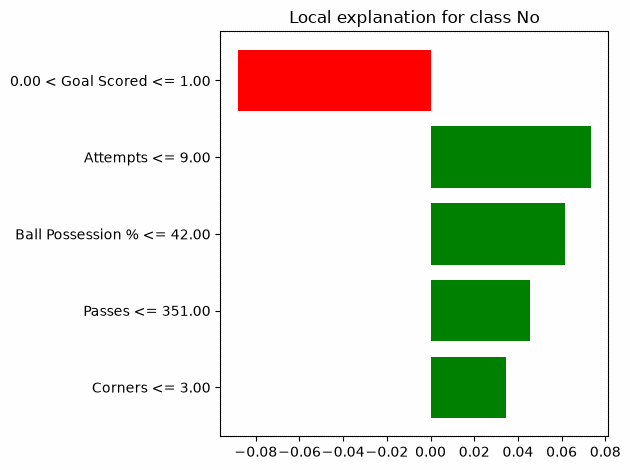

In [14]:
#| label: lime-explain
explainer = lime.lime_tabular.LimeTabularExplainer(
    np.array(X_train), feature_names=X.columns,
    class_names=['No', 'Yes'])

exp = explainer.explain_instance(np.array(X_test.iloc[0, :]), classifier_RF.predict_proba,
                                 num_features=5, top_labels=1)
exp.as_pyplot_figure(label=exp.available_labels()[0])
plt.tight_layout()
plt.show()

/home/yolo/.venvs/jupyter/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


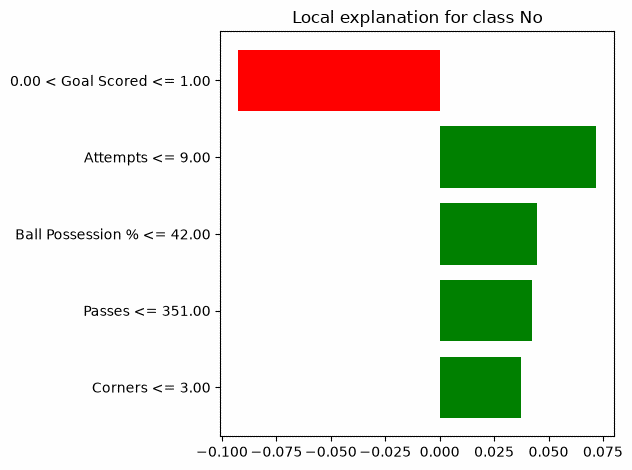

/home/yolo/.venvs/jupyter/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


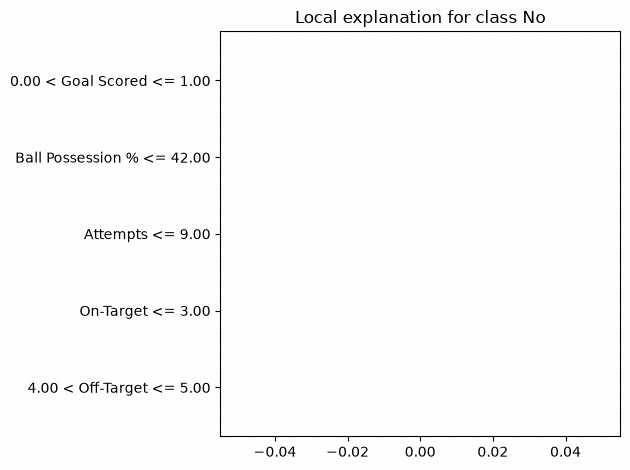

In [15]:
#| label: lime-kernel-width
# Large kernel width: the neighborhood is wide, the explanation approaches a
# global surrogate.
explainer_wide = lime.lime_tabular.LimeTabularExplainer(
    np.array(X_train), feature_names=X.columns,
    class_names=['No', 'Yes'], kernel_width=10)
exp = explainer_wide.explain_instance(np.array(X_test.iloc[0, :]), classifier_RF.predict_proba,
                                      num_features=5, top_labels=1)
exp.as_pyplot_figure(label=exp.available_labels()[0])
plt.tight_layout()
plt.show()

# Very small kernel width: the explanation is extremely local and unstable.
explainer_narrow = lime.lime_tabular.LimeTabularExplainer(
    np.array(X_train), feature_names=X.columns,
    class_names=['No', 'Yes'], kernel_width=0.001)
exp = explainer_narrow.explain_instance(np.array(X_test.iloc[0, :]), classifier_RF.predict_proba,
                                        num_features=5, top_labels=1)
exp.as_pyplot_figure(label=exp.available_labels()[0])
plt.tight_layout()
plt.show()